# Regression

The objective of the regression analysis is to examine whether linguistic sentiment in annual corporate leadership communication is associated with Leadership Context and National Environment, after accounting for the valence of the underlying information and relevant temporal characteristics.

Three hypotheses are investigated:

- H1: Sentiment varies systematically across Leadership Contexts after controlling for Information Valence.

- H2: Sentiment differs between German and Japanese companies after controlling for Leadership Context, Information Valence, and other included controls.

- H3: The association between Leadership Context and sentiment differs between German and Japanese corporate leadership communications.

**Ordinary Least Squares (OLS) regressions** are estimated separately for Financial-RoBERTa and FinBERT. This approach enables comparisons of the estimated relationships across two alternative sentiment measurements without averaging their outputs.

## 1. Dataset Preparation

The four company-level sentiment datasets are combined into a single analytical dataset containing observations from Adidas, Puma, Asics, and Mizuno over the period 2020–2025.

The initial dataset contains **592 textual segments**. For the primary regression analysis, observations classified as OTHER are excluded because this category does not represent one of the six substantive Leadership Contexts examined in the hypotheses. This exclusion removes 102 observations, leaving **490 observations** for the primary regression models.

Germany accounts for 256 observations and Japan for 234 observations. The regression sample contains all six substantive Leadership Context categories, and no observations are excluded because of missing values in the required variables.

Both sentiment models are evaluated using the same observations to ensure comparability.

In [31]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import patsy
from IPython.display import display
from matplotlib.backends.backend_pdf import PdfPages

COMPANIES = {
    "adidas": "Germany",
    "puma": "Germany",
    "asics": "Japan",
    "mizuno": "Japan"
}

SENTIMENT_MODELS = ("financial_roberta", "finbert")

CONTEXTS = (
    "PERF", "STRAT", "MARKET",
    "CHALL", "PEOPLE", "STAKE"
)

filenames = [
    f"{name}_sentiment.xlsx"
    for name in COMPANIES
]

folders = [
    Path("../data/processed"),
    Path("data/processed"),
    Path("."),
    Path("/mnt/data")
]

DATA_DIR = next(
    (
        p for p in folders
        if all((p / f).exists() for f in filenames)
    ),
    None
)

frames = []

for company, country in COMPANIES.items():

    d = pd.read_excel(
        DATA_DIR / f"{company}_sentiment.xlsx"
    )

    d.columns = [
        re.sub(
            r"[^a-z0-9]+", "_", str(c).lower()
        ).strip("_")
        for c in d.columns
    ]

    d = d.rename(columns={
        "leadership_context": "context",
        "information_valence": "valence",
        "information_value": "valence",
        "id": "segment_id"
    })

    required = [
        "context", "valence", "year"
    ] + [
        f"{m}_{v}_prob"
        for m in SENTIMENT_MODELS
        for v in ("positive", "neutral", "negative")
    ]

    missing = sorted(
        set(required) - set(d.columns)
    )

    if missing:
        raise ValueError(
            f"{company}: missing columns {missing}"
        )

    d["company"] = company
    d["country"] = country

    frames.append(d)

raw = pd.concat(
    frames,
    ignore_index=True
)

raw["context"] = (
    raw["context"]
    .astype("string")
    .str.strip()
    .str.upper()
)

raw["valence"] = (
    raw["valence"]
    .astype("string")
    .str.strip()
    .str.lower()
)

raw["year"] = pd.to_numeric(
    raw["year"],
    errors="coerce"
)

# Calculate the sentiment score separately
# for Financial-RoBERTa and FinBERT.

for m in SENTIMENT_MODELS:

    probs = [
        f"{m}_{x}_prob"
        for x in ("positive", "neutral", "negative")
    ]

    raw[probs] = raw[probs].apply(
        pd.to_numeric,
        errors="coerce"
    )

    valid = raw[probs].notna().all(axis=1)

    if not np.isclose(
        raw.loc[valid, probs].sum(axis=1),
        1,
        atol=1e-3
    ).all():
        raise ValueError(
            f"{m} probabilities do not sum to 1"
        )

    raw[f"{m}_score"] = (
        raw[f"{m}_positive_prob"]
        - raw[f"{m}_negative_prob"]
    )

print("Input folder:", DATA_DIR.resolve())
print("Total observations:", len(raw))

display(
    raw.groupby(["country", "company"])
    .size()
    .rename("N")
    .to_frame()
)

Input folder: /Users/Saowalak/Desktop/CEOCommunication/data/processed
Total observations: 592


N
country company     
Germany adidas   219
        puma     105
Japan   asics    206
        mizuno    62

## 2. Regression Model Specification

The dependent variable is the continuous linguistic sentiment score calculated independently for Financial-RoBERTa and FinBERT. For each segment, the score is calculated as the probability of positive sentiment minus the probability of negative sentiment, producing values between −1 and +1.

The main explanatory variables are Leadership Context and Country. Leadership Context comprises six categories: PERF, STRAT, MARKET, CHALL, PEOPLE, and STAKE. Country distinguishes German and Japanese companies using headquarters location.

Information Valence is included as a categorical control with three levels: positive, neutral, and negative. Reporting Year is included as a categorical control to account for temporal variation.

The reference categories are PERF for Leadership Context, Germany for Country, and neutral for Information Valence.

Two regression specifications are estimated for each sentiment model:

**Model 1 — Additive specification:** Examines the associations between Leadership Context, Country, and linguistic sentiment, controlling for Information Valence and Year. This specification addresses H1 and H2.

**Model 2 — Interaction specification:** Extends the additive model by including interactions between Leadership Context and Country. This specification addresses H3.

**Communication Type is excluded from these estimated specifications because it is perfectly confounded with Country in the observed dataset.** German observations consist of letters and interviews, whereas Japanese observations consist of messages. Consequently, independent coefficients for Country and the complete set of Communication Type categories cannot be identified.

Standard errors are clustered using company-by-reporting-year groups as an approximation of dependence among segments originating from related corporate communications. Since the dataset comprises only four companies, statistical inference, especially for country-level comparisons, remains exploratory.

In [19]:
required = [
    "context",
    "valence",
    "year",
    "company",
    "country"
] + [
    f"{m}_score"
    for m in SENTIMENT_MODELS
]

analysis = raw.loc[
    raw["context"].isin(CONTEXTS)
].dropna(subset=required).copy()

# Validate information valence

if not analysis["valence"].isin([
    "neutral", "positive", "negative"
]).all():
    raise ValueError(
        "Unexpected Information Valence labels"
    )

# Validate reporting years

if not analysis["year"].between(
    2020, 2025
).all():
    raise ValueError(
        "Unexpected reporting year"
    )

analysis["year"] = analysis["year"].astype(int)

# Set reference categories

analysis["context"] = pd.Categorical(
    analysis["context"],
    categories=CONTEXTS
)

analysis["country"] = pd.Categorical(
    analysis["country"],
    categories=["Germany", "Japan"]
)

analysis["valence"] = pd.Categorical(
    analysis["valence"],
    categories=["neutral", "positive", "negative"]
)

# Company-year clusters are used as a proxy
# for dependence within reporting documents.

analysis["cluster_id"] = (
    analysis["company"].astype(str)
    + "_"
    + analysis["year"].astype(str)
)

print("Primary sample:", len(analysis))

print(
    "Number of clusters:",
    analysis["cluster_id"].nunique()
)

print(
    "OTHER observations excluded:",
    raw["context"].eq("OTHER").sum()
)

display(
    pd.crosstab(
        analysis["country"],
        analysis["context"]
    )
)

# Inspect whether Communication Type can be controlled for.

if "communication_type" in analysis.columns:

    display(
        pd.crosstab(
            analysis["country"],
            analysis["communication_type"]
        )
    )

    print(
        "Communication Type omitted from primary regressions."
    )

# Check original and subdivided segment identifiers.

if "segment_id" in raw.columns:

    chk = raw[
        ["company", "segment_id"]
    ].dropna().copy()

    chk["segment_id"] = (
        chk["segment_id"].astype(str).str.strip()
    )

    chk["parent"] = chk["segment_id"].str.replace(
        r"-\d+$", "", regex=True
    )

    chk["suffix"] = chk["segment_id"].str.extract(
        r"-(\d+)$",
        expand=False
    )

    mixed = chk.groupby(
        ["company", "parent"]
    )["suffix"].agg(
        lambda s: (
            "00" in set(s.dropna())
            and any(
                x != "00" for x in s.dropna()
            )
        )
    )

    print(
        "Original and subdivided IDs to review:",
        int(mixed.sum())
    )

Primary sample: 490
Number of clusters: 23
OTHER observations excluded: 102


context,PERF,STRAT,MARKET,CHALL,PEOPLE,STAKE
country,,,,,,
Germany,65,58,47,28,38,20
Japan,30,75,24,24,25,56


communication_type,interview,interview,letter,message
country,,,,
Germany,59,57,140,0
Japan,0,0,0,234


Communication Type omitted from primary regressions.
Original and subdivided IDs to review: 120


## 3. Descriptive Analysis

Descriptive statistics are calculated to examine the distribution of linguistic sentiment across Leadership Contexts and countries before estimating the regression models.

The two sentiment models produce positively correlated but non-identical scores. The Pearson correlation between their continuous sentiment scores is approximately **0.574**, while the mean absolute difference between scores is approximately **0.394**. These results suggest that Financial-RoBERTa and FinBERT capture overlapping aspects of linguistic evaluation but differ in their assessment of individual segments.

The distribution of Leadership Contexts also differs between the two national groups. The German sample contains relatively more Business Performance and Product, Brand & Market segments, whereas the Japanese sample contains relatively more Strategy and Stakeholders, Society & Sustainability segments.

These descriptive differences motivate the multivariable regression analysis, which examines the relationship between Leadership Context, Country, and sentiment while accounting for Information Valence and Year.

,country,context,N,roberta_mean,finbert_mean
0,Germany,PERF,65,0.689,0.449
1,Germany,STRAT,58,0.591,0.411
2,Germany,MARKET,47,0.811,0.467
3,Germany,CHALL,28,-0.147,-0.068
4,Germany,PEOPLE,38,0.602,0.444
5,Germany,STAKE,20,0.368,0.127
6,Japan,PERF,30,0.753,0.631
7,Japan,STRAT,75,0.692,0.451
8,Japan,MARKET,24,0.575,0.334
9,Japan,CHALL,24,0.438,0.344


Pearson correlation between sentiment models: 0.574


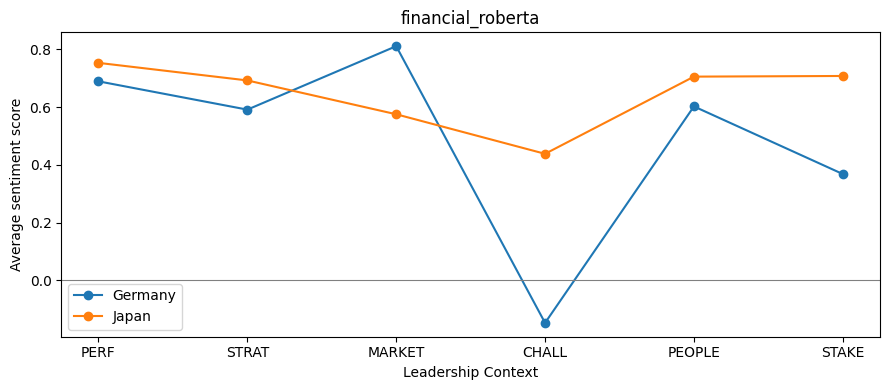

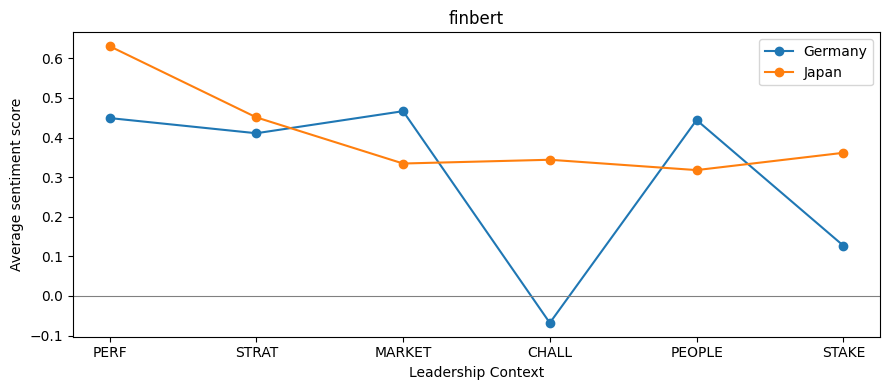

In [20]:
summary = (
    analysis.groupby(
        ["country", "context"],
        observed=True
    )
    .agg(
        N=("company", "size"),
        roberta_mean=(
            "financial_roberta_score", "mean"
        ),
        finbert_mean=(
            "finbert_score", "mean"
        )
    )
    .reset_index()
)

display(summary.round(3))

# Agreement between the two sentiment scores

score_columns = [
    f"{m}_score"
    for m in SENTIMENT_MODELS
]

correlation = analysis[
    score_columns
].corr().iloc[0, 1]

print(
    "Pearson correlation between sentiment models:",
    round(correlation, 3)
)

# Average sentiment by context and country

for m in SENTIMENT_MODELS:

    fig, ax = plt.subplots(figsize=(9, 4))

    for country, values in analysis.groupby(
        "country",
        observed=True
    ):

        by_context = (
            values.groupby(
                "context",
                observed=True
            )[f"{m}_score"]
            .mean()
            .reindex(CONTEXTS)
        )

        ax.plot(
            CONTEXTS,
            by_context,
            marker="o",
            label=country
        )

    ax.set_xlabel("Leadership Context")
    ax.set_ylabel("Average sentiment score")
    ax.set_title(m)
    ax.legend()

    ax.axhline(
        0,
        color="gray",
        linewidth=0.8
    )

    plt.tight_layout()
    plt.show()

## 4. Estimate the regression models

In [21]:
# Define explanatory variables and reference categories

C_CONTEXT = 'C(context, Treatment(reference="PERF"))'

C_COUNTRY = 'C(country, Treatment(reference="Germany"))'

C_VALENCE = 'C(valence, Treatment(reference="neutral"))'


# Define regression estimation function

def fit(formula, data=analysis, method="cluster"):

    regression = smf.ols(
        formula,
        data=data
    )

    if method == "cluster":

        result = regression.fit(
            cov_type="cluster",
            cov_kwds={
                "groups": data["cluster_id"]
            },
            use_t=True
        )

    elif method == "HC3":

        result = regression.fit(
            cov_type="HC3",
            use_t=True
        )

    else:
        raise ValueError("Unknown covariance method")

    if result.model.rank != len(result.params):
        raise ValueError(
            f"Collinearity detected: {formula}"
        )

    return result


# Run regressions separately for each sentiment model

models = {}

for m in SENTIMENT_MODELS:

    y = f"{m}_score"

    # Model 1: Additive regression (H1 + H2)

    formula_additive = (
        f"{y} ~ "
        f"{C_CONTEXT} + "
        f"{C_COUNTRY} + "
        f"{C_VALENCE} + "
        "C(year)"
    )

    # Model 2: Interaction regression (H3)

    formula_interaction = (
        f"{y} ~ "
        f"{C_CONTEXT} * {C_COUNTRY} + "
        f"{C_VALENCE} + "
        "C(year)"
    )

    additive = fit(formula_additive)
    interaction = fit(formula_interaction)

    models[m] = {
        "additive": additive,
        "interaction": interaction
    }

    print("\n", "=" * 60)
    print("SENTIMENT MODEL:", m.upper())
    print("=" * 60)

    print("\nADDITIVE REGRESSION")
    print(additive.summary())

    print("\nINTERACTION REGRESSION")
    print(interaction.summary())

    print(
        "\nAdditive R-squared:",
        round(additive.rsquared, 3)
    )

    print(
        "Interaction R-squared:",
        round(interaction.rsquared, 3)
    )


SENTIMENT MODEL: FINANCIAL_ROBERTA

ADDITIVE REGRESSION
                               OLS Regression Results                              
Dep. Variable:     financial_roberta_score   R-squared:                       0.309
Model:                                 OLS   Adj. R-squared:                  0.290
Method:                      Least Squares   F-statistic:                     22.43
Date:                     Sun, 25 Oct 2026   Prob (F-statistic):           1.05e-09
Time:                             21:40:21   Log-Likelihood:                -331.03
No. Observations:                      490   AIC:                             690.1
Df Residuals:                          476   BIC:                             748.8
Df Model:                               13                                         
Covariance Type:                   cluster                                         
                                                             coef    std err          t      P>|t|     

# Statistical tests for H1, H2 and H3

In [22]:
# Identify regression coefficient names

def terms_for(result, kind):

    terms = list(result.params.index)

    if kind == "context":

        return [
            x for x in terms
            if "C(context" in x and ":" not in x
        ]

    if kind == "interaction":

        return [
            x for x in terms
            if "C(context" in x
            and "C(country" in x
            and ":" in x
        ]

    if kind == "country":

        return [
            x for x in terms
            if "C(country" in x and ":" not in x
        ]

    raise ValueError(kind)


# Joint F-test for H1 and H3

def joint_f(result, term_names):

    R = np.zeros((
        len(term_names),
        len(result.params)
    ))

    for i, name in enumerate(term_names):

        R[
            i,
            result.params.index.get_loc(name)
        ] = 1

    test = result.wald_test(
        R,
        use_f=True,
        scalar=True
    )

    return {
        "F": float(test.statistic),
        "p": float(test.pvalue),
        "df_num": len(term_names),
        "df_den": float(test.df_denom)
    }


# Test the adjusted country coefficient for H2

def country_coefficient(result):

    name, = terms_for(result, "country")

    ci = result.conf_int().loc[name]

    return {
        "coefficient": float(result.params[name]),
        "p": float(result.pvalues[name]),
        "CI_low": float(ci.iloc[0]),
        "CI_high": float(ci.iloc[1])
    }


# Test the three hypotheses for both models

rows = []

for m in SENTIMENT_MODELS:

    additive = models[m]["additive"]
    interaction = models[m]["interaction"]

    h1_terms = terms_for(additive, "context")
    h3_terms = terms_for(interaction, "interaction")

    assert len(h1_terms) == 5
    assert len(h3_terms) == 5

    # H1: Leadership Context

    h1 = joint_f(
        additive,
        h1_terms
    )

    # H2: Country

    h2 = country_coefficient(
        additive
    )

    # H3: Context x Country

    h3 = joint_f(
        interaction,
        h3_terms
    )

    rows.extend([
        {
            "model": m,
            "hypothesis": "H1",
            **h1
        },
        {
            "model": m,
            "hypothesis": "H2",
            **h2
        },
        {
            "model": m,
            "hypothesis": "H3",
            **h3
        }
    ])

hypotheses = pd.DataFrame(rows)

print("HYPOTHESIS TESTING RESULTS")

display(
    hypotheses.round(4)
)

HYPOTHESIS TESTING RESULTS


,model,hypothesis,F,p,df_num,df_den,coefficient,CI_low,CI_high
0,financial_roberta,H1,1.8469,0.1451,5.0,22.0,NaN,NaN,NaN
1,financial_roberta,H2,NaN,0.0002,NaN,NaN,0.1775,0.0960,0.2590
2,financial_roberta,H3,5.1074,0.0029,5.0,22.0,NaN,NaN,NaN
3,finbert,H1,7.5655,0.0003,5.0,22.0,NaN,NaN,NaN
4,finbert,H2,NaN,0.0140,NaN,NaN,0.1262,0.0281,0.2242
5,finbert,H3,4.0139,0.0097,5.0,22.0,NaN,NaN,NaN


## Regression coefficient tables

In [23]:
coef_rows = []

for m in SENTIMENT_MODELS:

    for specification, result in models[m].items():

        ci = result.conf_int()

        for term in result.params.index:

            coef_rows.append({
                "model": m,
                "specification": specification,
                "term": term,
                "coefficient": result.params[term],
                "SE": result.bse[term],
                "p": result.pvalues[term],
                "CI_low": ci.loc[term].iloc[0],
                "CI_high": ci.loc[term].iloc[1]
            })

coefficients = pd.DataFrame(coef_rows)

print("REGRESSION COEFFICIENTS")

display(
    coefficients.round(4)
)

REGRESSION COEFFICIENTS


,model,specification,term,coefficient,SE,p,CI_low,CI_high
0,financial_roberta,additive,Intercept,0.6123,0.0697,0.0000,0.4678,0.7567
1,financial_roberta,additive,"C(context, Treatment(reference=""PERF""))[T.STRAT]",-0.0637,0.0800,0.4344,-0.2297,0.1022
2,financial_roberta,additive,"C(context, Treatment(reference=""PERF""))[T.MARKET]",-0.0116,0.0689,0.8673,-0.1545,0.1312
3,financial_roberta,additive,"C(context, Treatment(reference=""PERF""))[T.CHALL]",-0.3196,0.1307,0.0229,-0.5906,-0.0486
4,financial_roberta,additive,"C(context, Treatment(reference=""PERF""))[T.PEOPLE]",-0.1484,0.0984,0.1457,-0.3524,0.0556
...,...,...,...,...,...,...,...,...
61,finbert,interaction,"C(context, Treatment(reference=""PERF""))[T.STRA...",-0.0951,0.0945,0.3250,-0.2911,0.1008
62,finbert,interaction,"C(context, Treatment(reference=""PERF""))[T.MARK...",-0.2100,0.1119,0.0738,-0.4421,0.0220
63,finbert,interaction,"C(context, Treatment(reference=""PERF""))[T.CHAL...",0.1576,0.1460,0.2919,-0.1451,0.4604
64,finbert,interaction,"C(context, Treatment(reference=""PERF""))[T.PEOP...",-0.2379,0.0865,0.0117,-0.4172,-0.0585


## Interaction effects and adjusted comparisons (H3)

ADJUSTED COUNTRY DIFFERENCES BY CONTEXT


,model,context,difference,estimate,p,CI_low,CI_high
0,financial_roberta,PERF,Japan - Germany,0.047,0.606,-0.139,0.233
1,financial_roberta,STRAT,Japan - Germany,0.152,0.133,-0.050,0.355
2,financial_roberta,MARKET,Japan - Germany,-0.100,0.365,-0.326,0.125
3,financial_roberta,CHALL,Japan - Germany,0.447,0.019,0.081,0.813
4,financial_roberta,PEOPLE,Japan - Germany,0.206,0.121,-0.059,0.471
5,financial_roberta,STAKE,Japan - Germany,0.441,0.000,0.264,0.619
6,finbert,PERF,Japan - Germany,0.181,0.024,0.026,0.336
7,finbert,STRAT,Japan - Germany,0.086,0.346,-0.099,0.270
8,finbert,MARKET,Japan - Germany,-0.029,0.740,-0.209,0.151
9,finbert,CHALL,Japan - Germany,0.339,0.003,0.131,0.546


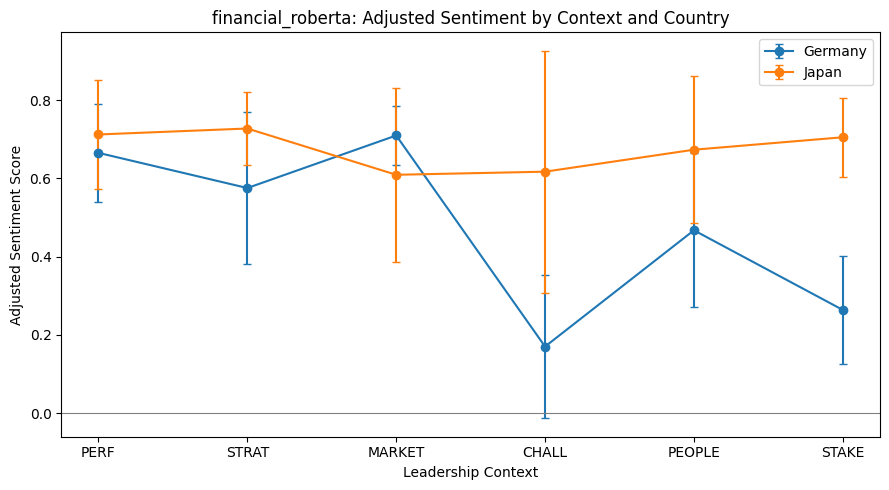

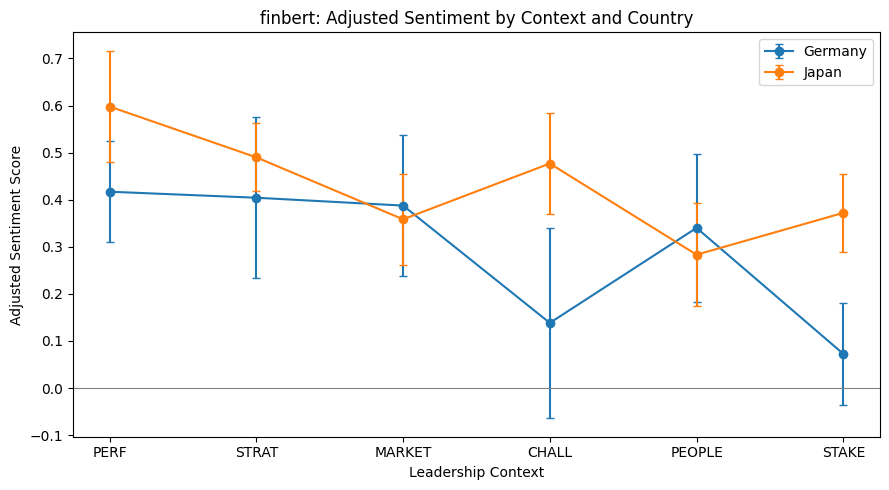

In [24]:
# Build average model-design vectors

def avg_design(result, sample, context, country):

    new = sample.copy()

    new["context"] = context
    new["country"] = country

    design = patsy.build_design_matrices(
        [result.model.data.design_info],
        new,
        return_type="dataframe"
    )[0]

    return design.mean(axis=0).to_numpy()


# Calculate adjusted estimates and confidence intervals

def contrast(result, L):

    test = result.t_test(L)

    ci = np.asarray(
        test.conf_int()
    ).ravel()

    return {
        "estimate": float(
            np.asarray(test.effect).item()
        ),
        "p": float(
            np.asarray(test.pvalue).item()
        ),
        "CI_low": float(ci[0]),
        "CI_high": float(ci[1])
    }


margin_rows = []
contrast_rows = []

for m in SENTIMENT_MODELS:

    result = models[m]["interaction"]

    for context in CONTEXTS:

        de = avg_design(
            result,
            analysis,
            context,
            "Germany"
        )

        jp = avg_design(
            result,
            analysis,
            context,
            "Japan"
        )

        # Adjusted sentiment for each country

        for country, L in [
            ("Germany", de),
            ("Japan", jp)
        ]:

            margin_rows.append({
                "model": m,
                "context": context,
                "country": country,
                **contrast(result, L)
            })

        # Adjusted Japan - Germany difference

        contrast_rows.append({
            "model": m,
            "context": context,
            "difference": "Japan - Germany",
            **contrast(result, jp - de)
        })


margins = pd.DataFrame(margin_rows)

country_context_differences = pd.DataFrame(
    contrast_rows
)

print("ADJUSTED COUNTRY DIFFERENCES BY CONTEXT")

display(
    country_context_differences.round(3)
)


# Plot adjusted sentiment scores

for m in SENTIMENT_MODELS:

    d = margins[
        margins["model"] == m
    ]

    fig, ax = plt.subplots(figsize=(9, 5))

    for country in ("Germany", "Japan"):

        e = (
            d[d["country"] == country]
            .set_index("context")
            .loc[list(CONTEXTS)]
        )

        ax.errorbar(
            CONTEXTS,
            e["estimate"],
            yerr=[
                e["estimate"] - e["CI_low"],
                e["CI_high"] - e["estimate"]
            ],
            fmt="o-",
            capsize=3,
            label=country
        )

    ax.set_title(
        f"{m}: Adjusted Sentiment by Context and Country"
    )

    ax.set_xlabel("Leadership Context")
    ax.set_ylabel("Adjusted Sentiment Score")

    ax.legend()

    ax.axhline(
        0,
        color="gray",
        linewidth=0.8
    )

    plt.tight_layout()
    plt.show()

## Robustness and Sensitivity Analysis

In [25]:
sensitivity_rows = []

for m in SENTIMENT_MODELS:

    for hypothesis, specification in [
        ("H1", "additive"),
        ("H2", "additive"),
        ("H3", "interaction")
    ]:

        original = models[m][specification]

        # Re-estimate using HC3 robust standard errors

        hc3 = fit(
            original.model.formula,
            method="HC3"
        )

        if hypothesis == "H2":

            result = country_coefficient(hc3)

        else:

            kind = (
                "context"
                if hypothesis == "H1"
                else "interaction"
            )

            result = joint_f(
                hc3,
                terms_for(hc3, kind)
            )

        sensitivity_rows.append({
            "model": m,
            "test": hypothesis,
            "method": "HC3",
            **result
        })

    # Company fixed-effects specification
    # Only H1 is tested because country is
    # determined by company membership.

    fe_formula = (
        f"{m}_score ~ "
        f"{C_CONTEXT} + "
        "C(company) + "
        f"{C_VALENCE} + "
        "C(year)"
    )

    fe = fit(fe_formula)

    sensitivity_rows.append({
        "model": m,
        "test": "H1",
        "method": "Company fixed effects",
        **joint_f(
            fe,
            terms_for(fe, "context")
        )
    })


sensitivity = pd.DataFrame(
    sensitivity_rows
)

print("ROBUSTNESS ANALYSIS")

display(
    sensitivity.round(4)
)

ROBUSTNESS ANALYSIS


,model,test,method,F,p,df_num,df_den,coefficient,CI_low,CI_high
0,financial_roberta,H1,HC3,2.8313,0.0156,5.0,476.0,NaN,NaN,NaN
1,financial_roberta,H2,HC3,NaN,0.0002,NaN,NaN,0.1775,0.0838,0.2712
2,financial_roberta,H3,HC3,2.9517,0.0123,5.0,471.0,NaN,NaN,NaN
3,financial_roberta,H1,Company fixed effects,1.7698,0.1608,5.0,22.0,NaN,NaN,NaN
4,finbert,H1,HC3,4.6705,0.0004,5.0,476.0,NaN,NaN,NaN
5,finbert,H2,HC3,NaN,0.0009,NaN,NaN,0.1262,0.0522,0.2001
6,finbert,H3,HC3,2.8792,0.0142,5.0,471.0,NaN,NaN,NaN
7,finbert,H1,Company fixed effects,8.6482,0.0001,5.0,22.0,NaN,NaN,NaN


## Export results

In [32]:
# Identify the project root using data/processed
if DATA_DIR.name == "processed" and DATA_DIR.parent.name == "data":
    PROJECT_ROOT = DATA_DIR.resolve().parent.parent
else:
    PROJECT_ROOT = Path.cwd().resolve()

TABLE_DIR = PROJECT_ROOT / "results" / "tables" / "regression"
FIGURE_DIR = PROJECT_ROOT / "results" / "figures" / "regression"

TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Tables:", TABLE_DIR)
print("Figures:", FIGURE_DIR)


Tables: /Users/Saowalak/Desktop/CEOCommunication/results/tables/regression
Figures: /Users/Saowalak/Desktop/CEOCommunication/results/figures/regression


In [33]:
def fmt_p(p):
    return "<0.001" if float(p) < 0.001 else f"{float(p):.3f}"


def fmt_ci(lo, hi):
    return f"[{lo:.3f}, {hi:.3f}]"


def pretty_term(term):
    if term == "Intercept":
        return "Intercept"

    match = re.search(
        r'C\(context.*?\)\[T\.([A-Z]+)\]', term
    )
    if match:
        c = match.group(1)
        return (
            f"Japan x {c} (vs PERF)"
            if ":" in term else f"{c} (vs PERF)"
        )

    match = re.search(
        r'C\(valence.*?\)\[T\.([a-z]+)\]', term
    )
    if match:
        return f"Valence: {match.group(1)} (vs neutral)"

    if "C(country" in term:
        return "Japan (vs Germany)"

    match = re.search(r'C\(year\)\[T\.(\d{4})\]', term)
    if match:
        return f"Year {match.group(1)} (vs 2020)"

    return term


def table_pdf(df, filename, title, note="", rows_per_page=22):
    df = (
        df.reset_index(drop=True)
        .astype(object)
        .fillna("-")
        .astype(str)
    )

    path = TABLE_DIR / filename
    pages = max(1, (len(df) + rows_per_page - 1) // rows_per_page)

    with PdfPages(path) as pdf:
        for page in range(pages):
            part = df.iloc[
                page * rows_per_page:
                (page + 1) * rows_per_page
            ]

            height = max(
                5.0,
                min(12.0, 2.7 + 0.36 * (len(part) + 1))
            )

            fig, ax = plt.subplots(figsize=(15, height))
            ax.axis("off")

            fig.text(
                0.035, 0.95, title,
                fontsize=15, weight="bold", va="top"
            )

            if pages > 1:
                fig.text(
                    0.965, 0.95,
                    f"Page {page + 1}/{pages}",
                    fontsize=9, ha="right"
                )

            ncol = len(df.columns)

            if ncol == 5 and df.columns[0] == "Term":
                widths = [0.40, 0.12, 0.12, 0.23, 0.13]
            else:
                widths = [1.0 / ncol] * ncol

            tab = ax.table(
                cellText=part.values.tolist(),
                colLabels=list(df.columns),
                colWidths=widths,
                cellLoc="center",
                colLoc="center",
                bbox=[0.035, 0.13, 0.93, 0.75]
            )

            tab.auto_set_font_size(False)
            tab.set_fontsize(8.8 if ncol <= 6 else 7.4)

            for (r, c), cell in tab.get_celld().items():
                cell.set_linewidth(0.35)
                cell.set_edgecolor("#c9c9c9")

                if r == 0:
                    cell.set_facecolor("#ebeff5")
                    cell.get_text().set_weight("bold")
                elif r % 2 == 0:
                    cell.set_facecolor("#f8f8f8")

                if c == 0:
                    cell.get_text().set_ha("left")

            if note:
                fig.text(
                    0.035, 0.055, note,
                    fontsize=8, va="bottom"
                )

            pdf.savefig(fig, bbox_inches="tight")
            plt.close(fig)

    print("Saved:", path)

In [34]:
# Descriptive statistics

descriptive_table = summary.rename(columns={
    "country": "Country",
    "context": "Context",
    "roberta_mean": "RoBERTa mean",
    "finbert_mean": "FinBERT mean"
}).copy()

for col in ["RoBERTa mean", "FinBERT mean"]:
    descriptive_table[col] = (
        descriptive_table[col].map(lambda x: f"{x:.3f}")
    )

table_pdf(
    descriptive_table,
    "01_descriptives.pdf",
    "Table 1. Descriptive sentiment by country and context",
    note="Unadjusted means; six substantive contexts; N = 490."
)


# H1, H2 and H3 tests

test_rows = []

for _, r in hypotheses.iterrows():
    is_h2 = r["hypothesis"] == "H2"

    test_rows.append({
        "Model": (
            "Financial-RoBERTa"
            if r["model"] == "financial_roberta"
            else "FinBERT"
        ),
        "Test": r["hypothesis"],
        "F(df1, df2)": (
            "-"
            if is_h2
            else f'{r["F"]:.3f} ({int(r["df_num"])}, {int(r["df_den"])})'
        ),
        "Country beta": (
            f'{r["coefficient"]:+.3f}' if is_h2 else "-"
        ),
        "95% CI": (
            fmt_ci(r["CI_low"], r["CI_high"]) if is_h2 else "-"
        ),
        "p": fmt_p(r["p"])
    })

table_pdf(
    pd.DataFrame(test_rows),
    "02_hypothesis_tests.pdf",
    "Table 2. Regression hypothesis tests",
    note=(
        "H1 and H3: joint F-tests. H2: additive-model country "
        "coefficient. Inference clustered by company-year."
    )
)

Saved: /Users/Saowalak/Desktop/CEOCommunication/results/tables/regression/01_descriptives.pdf
Saved: /Users/Saowalak/Desktop/CEOCommunication/results/tables/regression/02_hypothesis_tests.pdf


In [36]:
for m in SENTIMENT_MODELS:
    for specification, result in models[m].items():

        ci = result.conf_int()
        rows = []

        for term in result.params.index:
            rows.append({
                "Term": pretty_term(term),
                "Estimate": f"{result.params[term]:+.3f}",
                "SE": f"{result.bse[term]:.3f}",
                "95% CI": fmt_ci(
                    ci.loc[term].iloc[0],
                    ci.loc[term].iloc[1]
                ),
                "p": fmt_p(result.pvalues[term])
            })

        model_name = (
            "Financial-RoBERTa"
            if m == "financial_roberta"
            else "FinBERT"
        )

        table_pdf(
            pd.DataFrame(rows),
            f"03_coefficients_{m}_{specification}.pdf",
            f"OLS coefficients: {model_name}, {specification}",
            note=(
                f"N = {int(result.nobs)}; "
                f"R² = {result.rsquared:.3f}; "
                "company-year-clustered standard errors."
            )
        )

Saved: /Users/Saowalak/Desktop/CEOCommunication/results/tables/regression/03_coefficients_financial_roberta_additive.pdf
Saved: /Users/Saowalak/Desktop/CEOCommunication/results/tables/regression/03_coefficients_financial_roberta_interaction.pdf
Saved: /Users/Saowalak/Desktop/CEOCommunication/results/tables/regression/03_coefficients_finbert_additive.pdf
Saved: /Users/Saowalak/Desktop/CEOCommunication/results/tables/regression/03_coefficients_finbert_interaction.pdf


In [37]:
model_names = {
    "financial_roberta": "Financial-RoBERTa",
    "finbert": "FinBERT"
}

# Adjusted sentiment estimates

adjusted = margins.copy()

adjusted["Model"] = adjusted["model"].map(model_names)
adjusted["Adjusted mean"] = adjusted["estimate"].map(
    lambda x: f"{x:+.3f}"
)
adjusted["95% CI"] = adjusted.apply(
    lambda r: fmt_ci(r.CI_low, r.CI_high),
    axis=1
)

table_pdf(
    adjusted[
        ["Model", "context", "country", "Adjusted mean", "95% CI"]
    ].rename(columns={
        "context": "Context",
        "country": "Country"
    }),
    "04_adjusted_margins.pdf",
    "Table 4. Adjusted sentiment by context and country",
    note="Interaction models; controls averaged over the analytical sample."
)


# Adjusted country differences by context

contrasts = country_context_differences.copy()

contrasts["Model"] = contrasts["model"].map(model_names)
contrasts["Japan - Germany"] = contrasts["estimate"].map(
    lambda x: f"{x:+.3f}"
)
contrasts["95% CI"] = contrasts.apply(
    lambda r: fmt_ci(r.CI_low, r.CI_high),
    axis=1
)
contrasts["p"] = contrasts["p"].map(fmt_p)

table_pdf(
    contrasts[
        ["Model", "context", "Japan - Germany", "95% CI", "p"]
    ].rename(columns={"context": "Context"}),
    "05_country_context_differences.pdf",
    "Table 5. Adjusted country differences by context",
    note="Exploratory contrasts; p-values not adjusted for multiple comparisons."
)


# Robustness analysis

rob = sensitivity.copy()

rob["Model"] = rob["model"].map(model_names)

rob["Statistic"] = rob.apply(
    lambda r: (
        f'F = {r["F"]:.3f}'
        if pd.notna(r["F"])
        else f'beta = {r["coefficient"]:+.3f}'
    ),
    axis=1
)

rob["p"] = rob["p"].map(fmt_p)

table_pdf(
    rob[
        ["Model", "test", "method", "Statistic", "p"]
    ].rename(columns={
        "test": "Test",
        "method": "Estimator"
    }),
    "06_robustness.pdf",
    "Table 6. Robustness analyses",
    note="HC3 and company-fixed-effects sensitivity specifications."
)

Saved: /Users/Saowalak/Desktop/CEOCommunication/results/tables/regression/04_adjusted_margins.pdf
Saved: /Users/Saowalak/Desktop/CEOCommunication/results/tables/regression/05_country_context_differences.pdf
Saved: /Users/Saowalak/Desktop/CEOCommunication/results/tables/regression/06_robustness.pdf


In [38]:
for m in SENTIMENT_MODELS:

    label = model_names[m]

    # Figure 1: Unadjusted mean sentiment

    fig, ax = plt.subplots(figsize=(9, 5))

    for country in ["Germany", "Japan"]:
        d = analysis[analysis["country"] == country]

        means = (
            d.groupby("context", observed=True)[f"{m}_score"]
            .mean()
            .reindex(CONTEXTS)
        )

        ax.plot(
            CONTEXTS,
            means.to_numpy(),
            marker="o",
            label=country
        )

    ax.set(
        title=f"Observed mean sentiment by context — {label}",
        xlabel="Leadership Context",
        ylabel="Mean sentiment (-1 to +1)"
    )
    ax.axhline(0, linewidth=0.8, color="gray")
    ax.legend()
    fig.tight_layout()

    fig.savefig(
        FIGURE_DIR / f"01_descriptive_{m}.pdf",
        bbox_inches="tight"
    )
    plt.close(fig)


    # Figure 2: Adjusted sentiment by context and country

    d = margins[margins["model"] == m]

    fig, ax = plt.subplots(figsize=(9, 5))

    for country in ["Germany", "Japan"]:

        q = (
            d[d["country"] == country]
            .set_index("context")
            .loc[list(CONTEXTS)]
        )

        ax.errorbar(
            CONTEXTS,
            q["estimate"],
            yerr=[
                q["estimate"] - q["CI_low"],
                q["CI_high"] - q["estimate"]
            ],
            marker="o",
            capsize=3,
            label=country
        )

    ax.set(
        title=f"Adjusted sentiment by context and country — {label}",
        xlabel="Leadership Context",
        ylabel="Adjusted sentiment (95% CI)"
    )
    ax.axhline(0, linewidth=0.8, color="gray")
    ax.legend()
    fig.tight_layout()

    fig.savefig(
        FIGURE_DIR / f"02_adjusted_context_country_{m}.pdf",
        bbox_inches="tight"
    )
    plt.close(fig)


    # Figure 3: Japan-minus-Germany contrasts

    q = (
        country_context_differences[
            country_context_differences["model"] == m
        ]
        .set_index("context")
        .loc[list(CONTEXTS)]
    )

    fig, ax = plt.subplots(figsize=(9, 5))

    ax.errorbar(
        CONTEXTS,
        q["estimate"],
        yerr=[
            q["estimate"] - q["CI_low"],
            q["CI_high"] - q["estimate"]
        ],
        marker="o",
        capsize=3
    )

    ax.set(
        title=f"Adjusted Japan-minus-Germany differences — {label}",
        xlabel="Leadership Context",
        ylabel="Japan - Germany (95% CI)"
    )
    ax.axhline(
        0,
        linewidth=0.8,
        linestyle="--",
        color="gray"
    )
    fig.tight_layout()

    fig.savefig(
        FIGURE_DIR / f"03_country_differences_{m}.pdf",
        bbox_inches="tight"
    )
    plt.close(fig)


print("Tables saved:", len(list(TABLE_DIR.glob("*.pdf"))))
print("Figures saved:", len(list(FIGURE_DIR.glob("*.pdf"))))

Tables saved: 9
Figures saved: 6
